# CPE 586 — Homework 3: Optimization and Linear Regression
**Format:** Google Colab notebook — theoretical answers and executable Python code  
**Unique package keyword:** `buttercookie`  
**GitHub repository:** https://github.com/buttercookiegh/hw00buttercookiegh  
**PyPI package:** https://pypi.org/project/buttercookie/ (version 0.4.0)  
**Commit hash:** f713161

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
print('NumPy:', np.__version__, '| PyTorch:', torch.__version__)

NumPy: 2.1.3 | PyTorch: 2.11.0+cpu


##Q1 — Automatic Differentiation and Expression Graph

Given
$$f(w,x,y,z)=wx+y^2z.$$
 $u=wx$, $q=y^2$, $v=qz$, and $f=u+v$.

The forward pass at $(w,x,y,z)=(1,2,3,4)$ gives
$$u=1\cdot2=2,\quad q=3^2=9,\quad v=9\cdot4=36,\quad f=38.$$

The reverse pass starts from $\partial f/\partial f=1$:
$$\frac{\partial f}{\partial u}=1,\qquad
\frac{\partial u}{\partial w}=x.$$
By the chain rule,
$$\boxed{\frac{\partial f}{\partial w}=\frac{\partial f}{\partial u}\frac{\partial u}{\partial w}=x=2.}$$

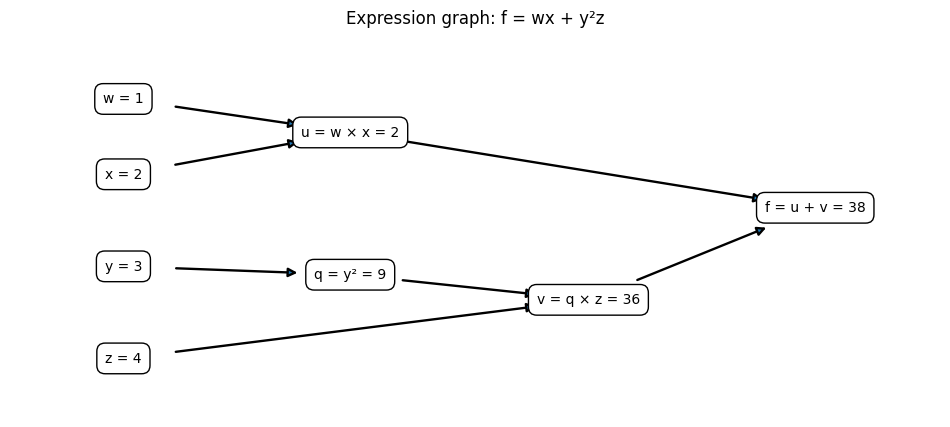

f = 38; df/dw = 2


In [65]:
# Expression graph + PyTorch verification
from matplotlib.patches import FancyArrowPatch

nodes = {
    'w': (0.0, 3.3, 'w = 1'),
    'x': (0.0, 2.4, 'x = 2'),
    'y': (0.0, 1.3, 'y = 3'),
    'z': (0.0, 0.2, 'z = 4'),
    'u': (2.0, 2.9, 'u = w × x = 2'),
    'q': (2.0, 1.2, 'q = y² = 9'),
    'v': (4.1, 0.9, 'v = q × z = 36'),
    'f': (6.1, 2.0, 'f = u + v = 38'),
}
connections = [('w','u'),('x','u'),('y','q'),('q','v'),('z','v'),('u','f'),('v','f')]
fig, ax = plt.subplots(figsize=(12, 5))
for a,b in connections:
    xa, ya, _ = nodes[a]
    xb, yb, _ = nodes[b]
    patch = FancyArrowPatch((xa,ya), (xb,yb), arrowstyle='-|>', mutation_scale=13,
                            linewidth=1.7, shrinkA=38, shrinkB=38)
    ax.add_patch(patch)
for key,(x,y,label) in nodes.items():
    ax.text(x,y,label,ha='center',va='center',fontsize=10,
            bbox={'boxstyle':'round,pad=0.6','fc':'white','ec':'black'})
ax.set(xlim=(-1.0,7.2),ylim=(-0.5,4.1),title='Expression graph: f = wx + y²z')
ax.axis('off')
plt.show()

w = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(2.0)
y = torch.tensor(3.0)
z = torch.tensor(4.0)
f = w*x + y.square()*z
f.backward()
print(f'f = {f.item():.0f}; df/dw = {w.grad.item():.0f}')
assert f.item() == 38.0 and w.grad.item() == 2.0

## Q2 — Unconstrained Optimization

### (a) $f(x)=x^2-4x+4$
$$f'(x)=2x-4=0\implies x=2;\qquad f''(x)=2>0.$$
Also $f(x)=(x-2)^2\ge 0$ for all $x$.

Unique global minimum at x=2;
minimum function value f(2)=0.

### (b) $f(x)=x^3-3x^2$
$$f'(x)=3x^2-6x=3x(x-2).$$
The critical points are $x=0$ and $x=2$. The second derivative is $f''(x)=6x-6$.

| Critical point | $f''(x)$ | Classification | Function value |
|---|---:|---|---:|
| $x=0$ | $-6$ | Local maximum | $f(0)=0$ |
| $x=2$ | $6$ | Local minimum | $f(2)=-4$ |

There is **no global maximum or global minimum on $\mathbb R$**, because this cubic is unbounded above and below.

### (c) $f(x,y)=x^2-y^2$
$$\nabla f(x,y)=\begin{bmatrix}2x\\-2y\end{bmatrix}.$$
Setting the gradient equal to zero gives the unique critical point $(0,0)$.

$$H=\begin{bmatrix}2&0\\0&-2\end{bmatrix},\quad \det(H)=-4<0.$$
$(0,0)$ is a saddle point. Indeed, $f(x,0)=x^2>0$ for nonzero $x$, while $f(0,y)=-y^2<0$ for nonzero $y$.

## Q3 — Constrained Optimization Using Lagrange Multipliers

Minimize $f(x,y,z)=x^2+y^2+z^2$ subject to $x+2y+z=6$.

**1. Lagrangian:**
$$\ L(x,y,z,\lambda)=x^2+y^2+z^2-\lambda(x+2y+z-6).$$

**2. First-order conditions:**
$$2x-\lambda=0,\qquad 2y-2\lambda=0,\qquad 2z-\lambda=0,\qquad x+2y+z=6.$$

**3. Critical point:**
From the first-order conditions, $x=\lambda/2$, $y=\lambda$, $z=\lambda/2$. Substituting into the constraint $x+2y+z=6$:

$$\frac{\lambda}{2} + 2\lambda + \frac{\lambda}{2} = 6 \quad\Rightarrow\quad 3\lambda = 6 \quad\Rightarrow\quad \lambda = 2$$

Therefore $x = 1$, $y = 2$, $z = 1$, giving the critical point $(1, 2, 1)$.

**4. Classify extrema:**

The Hessian of $\ L$ (same as the Hessian of $f$, since $g$ is linear) is

$$H = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 2 & 0 \\ 0 & 0 & 2 \end{bmatrix}$$

with eigenvalues $\{2, 2, 2\}$, all positive, so $H$ is positive definite.

There is only one critical point, $(1,2,1)$ is the **global minimum**:

$$f(1,2,1) = 1 + 4 + 1 = 6$$

**5. Explain the role of the constraint:**

Without the constraint, $f(x,y,z)=x^2+y^2+z^2$ has minimum value $0$ at the origin. The constraint restricts us to the plane $x+2y+z=6$.

## Q4 — Five Gradient Descent Updates

Using the Stochastic Gradient Descent technique to calculate the optimal value of $w_1$ for the cost function:

$$
J(w_1) = (w_1 - 5)^4 + (w_1 - 3)^2 + 4 \tag{1}
$$

with learning rate $\eta = 0.1$ and initial value $w_1^{(0)} = 2.0$. we do 5 iterations,

## 1. Gradient of the Cost Function


$$
\frac{\partial J(w_1)}{\partial w_1} = 4(w_1 - 5)^3 + 2(w_1 - 3)
$$

## 2. Gradient Descent Update Rule

$$
w_1^{(t+1)} \leftarrow w_1^{(t)} - \eta \frac{\partial J(w_1^{(t)})}{\partial w_1} = w_1^{(t)} - 0.1\left[4(w_1^{(t)} - 5)^3 + 2(w_1^{(t)} - 3)\right]
$$

## 3. Iterations (Starting from $w_1^{(0)} = 2.0$)

**Iteration 1:**

$$
\frac{\partial J(2)}{\partial w_1} = 4(2-5)^3 + 2(2-3) = 4(-27) - 2 = -110
$$

$$
w_1^{(1)} = 2.0 - 0.1(-110) = 2.0 + 11 = 13.0
$$

**Iteration 2:**

$$
\frac{\partial J(13)}{\partial w_1} = 4(13-5)^3 + 2(13-3) = 4(512) + 20 = 2068
$$

$$
w_1^{(2)} = 13.0 - 0.1(2068) = 13.0 - 206.8 = -193.8
$$

**Iteration 3:**

$$
\frac{\partial J(-193.8)}{\partial w_1} = 4(-193.8-5)^3 + 2(-193.8-3) = 4(-198.8)^3 - 393.6 = -31{,}427{,}842.69
$$

$$
w_1^{(3)} = -193.8 - 0.1(-31{,}427{,}842.69) = 3{,}142{,}590.47
$$

**Iteration 4:**

$$
\frac{\partial J(w_1^{(3)})}{\partial w_1} \approx 4(3{,}142{,}585.47)^3 \approx 1.24 \times 10^{20}
$$

$$
w_1^{(4)} \approx 3.14 \times 10^{6} - 0.1(1.24 \times 10^{20}) \approx -1.24 \times 10^{19}
$$

**Iteration 5:**

$$
\frac{\partial J(w_1^{(4)})}{\partial w_1} \approx 4(-1.24 \times 10^{19})^3 \approx -7.65 \times 10^{57}
$$

$$
w_1^{(5)} \approx -1.24 \times 10^{19} - 0.1(-7.65 \times 10^{57}) \approx 7.65 \times 10^{56}
$$

### Summary Table

| $t$ | $w_1^{(t)}$ | $J(w_1^{(t)})$ | $\partial J / \partial w_1$ at $w_1^{(t)}$ |
| --- | --- | --- | --- |
| 0 | $2$ | $86$ | $-110$ |
| 1 | $13$ | $4200$ | $2068$ |
| 2 | $-193.8$ | $1.56 \times 10^{9}$ | $-3.14 \times 10^{7}$ |
| 3 | $3.14 \times 10^{6}$ | $9.75 \times 10^{25}$ | $1.24 \times 10^{20}$ |
| 4 | $-1.24 \times 10^{19}$ | $2.38 \times 10^{76}$ | $-7.65 \times 10^{57}$ |
| 5 | $7.65 \times 10^{56}$ | $3.43 \times 10^{227}$ | — |

**The iterates diverge catastrophically.** Instead of approaching the minimum, $w_1$ oscillates with exponentially growing magnitude (positive $\to$ negative $\to$ positive $\dots$), and the cost function $J$ explodes.

## 4. Why Does It Diverge? (Role of the Learning Rate)

The learning rate $\eta = 0.1$ is too large for this cost function:

- At the start, $\left|J'(2)\right| = 110$, so the first step has size $0.1 \times 110 = 11$: the iterate jumps from $2$ to $13$, overshooting the minimum ($w^* \approx 4.16$)
- Since $J'(w_1) \sim 4(w_1-5)^3$, the gradient grows **cubically** as $w_1$ moves from 5, so each overshoot produces a larger gradient and a larger overshoot — a runaway loop reaching $w_1^{(5)} \approx 7.65 \times 10^{56}$.
- Stability requires $\eta < 2 / J''$, and $J''(2) = 12(3^2) + 2 = 110$, so we need $\eta < 2/110 \approx 0.018$. The chosen $\eta = 0.1$ exceeds this bound. (With $\eta = 0.01$, gradient descent converges to $w_1 \approx 4.1649$.)

## 5. Comparison with Partial Differentiation

Setting the derivative to zero:

$$4(w_1 - 5)^3 + 2(w_1 - 3) = 0 \quad\Rightarrow\quad w_1^* \approx 4.1649, \qquad J(w_1^*) \approx 5.8433$$

Since $J''(w_1) = 12(w_1 - 5)^2 + 2 > 0$ everywhere, $J$ is strictly convex, so this is the **unique global minimum**.

| Aspect | Gradient Descent ($\eta = 0.1$) | Partial Differentiation |
|---|---|---|
| Result after 5 iterations | Diverges: $w_1^{(5)} \approx 7.65 \times 10^{56}$ | $w_1^* \approx 4.1649$ directly |
| Optimality guarantee | Only if $\eta$ is small enough and enough iterations run | Yes — solves $J' = 0$ exactly; convexity confirms global min |
| Dependence on $\eta$ | Critical: too large → divergence; too small → slow | None |
| Type | Iterative, needs convergence check | Direct (one shot) |


With $\eta = 0.1$, gradient descent diverges ($2 \to 13 \to -193.8 \to \dots$) because the quartic term makes the gradient grow cubically and the learning rate is oversized.

## Q5 — Linear Regression and $L_2$ Regularization

Minimize the ridge-regression objective
$$L(\mathbf w)=\|\mathbf y-\mathbf X\mathbf w\|_2^2+\lambda\|\mathbf w\|_2^2,\quad \lambda\ge0.$$

Expand using $\|\mathbf v\|_2^2=\mathbf v^T\mathbf v$:
$$L=(\mathbf y-\mathbf X\mathbf w)^T(\mathbf y-\mathbf X\mathbf w)+\lambda\mathbf w^T\mathbf w.$$

Differentiate with respect to $\mathbf w$:
$$\nabla_{\mathbf w}L=-2\mathbf X^T(\mathbf y-\mathbf X\mathbf w)+2\lambda\mathbf w.$$

Set the gradient to zero and rearrange:
$$\mathbf X^T\mathbf X\,\hat{\mathbf w}+\lambda\hat{\mathbf w}=\mathbf X^T\mathbf y,$$
$$\boxed{\hat{\mathbf w}_{\rm ridge}=(\mathbf X^T\mathbf X+\lambda I)^{-1}\mathbf X^T\mathbf y}$$
for $\lambda>0$ (and $\mathbf X^T\mathbf X+\lambda I$ invertible). In numerical software, solve the linear system rather than explicitly forming the inverse.

**Original ordinary least squares:** $\hat{\mathbf w}_{\rm OLS}=(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y$ when $\mathbf X$ has full column rank.

**Effect of the penalty:** A positive $\lambda$ shrinks the coefficient magnitudes, improves conditioning, can reduce variance and overfitting, and introduces bias. Greater $\lambda$ causes stronger shrinkage.

## Q6 — Assumptions of Simple Linear Regression

For $Y_i = w_0 + w_1 X_i + \varepsilon_i$:

1. **Linearity in coefficients:** $\mathbb{E}[Y_i \mid X_i] = w_0 + w_1 X_i$ — the model is linear in its parameters.
2. **Zero mean errors:** $\mathbb{E}[\varepsilon_i \mid X_i] = 0$ — predictors don't correlate with the error; this makes OLS unbiased (Gauss–Markov: $\mathbb{E}[\hat{w}_j] = w_j$).
3. **Uncorrelated errors:** $\sigma[\varepsilon_i, \varepsilon_j] = 0,\ i \neq j$ — one error reveals nothing about another. Time-series driving data may violate this.
4. **Homoscedasticity:** $\mathrm{Var}(\varepsilon_i \mid X_i) = \sigma^2$, constant across predictor values — needed for classical OLS standard errors.
5. **Variation in the predictor:** $\sum_{i} (X_i - \bar{X})^2 > 0$; 0$  otherwise the slope can't be estimated.

# Practice

## Q7 — PyTorch Autograd Derivative
$$\tau(r)=2r\sqrt{\frac r{r_s}}\sqrt{1-\frac{r_s}{r}}
=\frac{2r\sqrt{r-r_s}}{\sqrt{r_s}},\quad r>r_s>0.$$

Analytically,
$$\boxed{\frac{d\tau}{dr}=\frac{3r-2r_s}{\sqrt{r_s}\sqrt{r-r_s}}}.$$

Use PyTorch double precision for $r=30000.1$ and $r_s=0.00887$.

In [66]:
# PyTorch autograd + analytic check
import torch

r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)
r_s = torch.tensor(0.00887, dtype=torch.float64)
tau = 2*r*torch.sqrt(r/r_s)*torch.sqrt(1-r_s/r)
tau.backward()
analytic = (3*r.detach()-2*r_s)/(torch.sqrt(r_s)*torch.sqrt(r.detach()-r_s))
print(f'tau = {tau.item():.10f}')
print(f'dtau/dr (autograd) = {r.grad.item():.10f}')
print(f'dtau/dr (analytic) = {analytic.item():.10f}')
assert torch.allclose(r.grad, analytic, rtol=1e-10)

tau = 110344877.0482753217
dtau/dr (autograd) = 5517.2260054138
dtau/dr (analytic) = 5517.2260054138


## Q8 — One-Variable Linear Regression with Scikit-Learn

**Dataset:** Toyota RAV4 CAN message CSV.  
**Independent variable:** `steer_angle` (X). **Response:** `yaw_rate` (y).  
**Split:** 75% training, 25% testing; `random_state=42` to reproduce the results.

The model is $\hat y=\hat\omega_0+\hat\omega_1x$. Its intercept, slope and test $R^2$ are computed directly from the downloaded data rather than supplied as estimated or fabricated constants.

In [67]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display

RAV4_URL = (
    'https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/'
    '2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv'
)
rav4_raw = pd.read_csv(RAV4_URL)
print('Raw shape:', rav4_raw.shape)
print('Columns:', rav4_raw.columns.tolist())

rav4 = rav4_raw[['steer_angle','yaw_rate']].copy()
for name in ['steer_angle', 'yaw_rate']:
    rav4[name] = pd.to_numeric(rav4[name], errors='coerce')
rav4 = rav4.replace([np.inf, -np.inf], np.nan).dropna()
print('Valid rows:', len(rav4))
display(rav4.head())

X = rav4[['steer_angle']].to_numpy()
y = rav4['yaw_rate'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
sk_model = SklearnLinearRegression()
sk_model.fit(X_train, y_train)
y_pred = sk_model.predict(X_test)

print('Train rows:',len(X_train),'| Test rows:',len(X_test))
print(f'Intercept (beta_0): {sk_model.intercept_:.10f}')
print(f'Slope (beta_1): {sk_model.coef_[0]:.10f}')
print(f'Fitted model: yaw_rate = {sk_model.intercept_:.6f} '
      f'+ ({sk_model.coef_[0]:.6f}) * steer_angle')
print(f'Test R²: {r2_score(y_test, y_pred):.8f}')
print(f'Test MSE: {mean_squared_error(y_test, y_pred):.8f}')

Raw shape: (8875, 16)
Columns: ['Clock', 'Time', 'speed', 'distance_covered', 'accely', 'yaw_rate', 'steer_rate', 'steer_angle', 'steer_fraction', 'wheel_speed_fl', 'wheel_speed_fr', 'wheel_speed_rl', 'wheel_speed_rr', 'lead_distance', 'acc_status', 'relative_vel']
Valid rows: 8875


,steer_angle,yaw_rate
0,0.0,-0.072
1,0.0,-0.072
2,0.0,-0.316
3,0.0,-0.316
4,0.0,-0.316


Train rows: 6656 | Test rows: 2219
Intercept (beta_0): -0.2071970543
Slope (beta_1): 0.0662084632
Fitted model: yaw_rate = -0.207197 + (0.066208) * steer_angle
Test R²: 0.65556438
Test MSE: 10.19606478


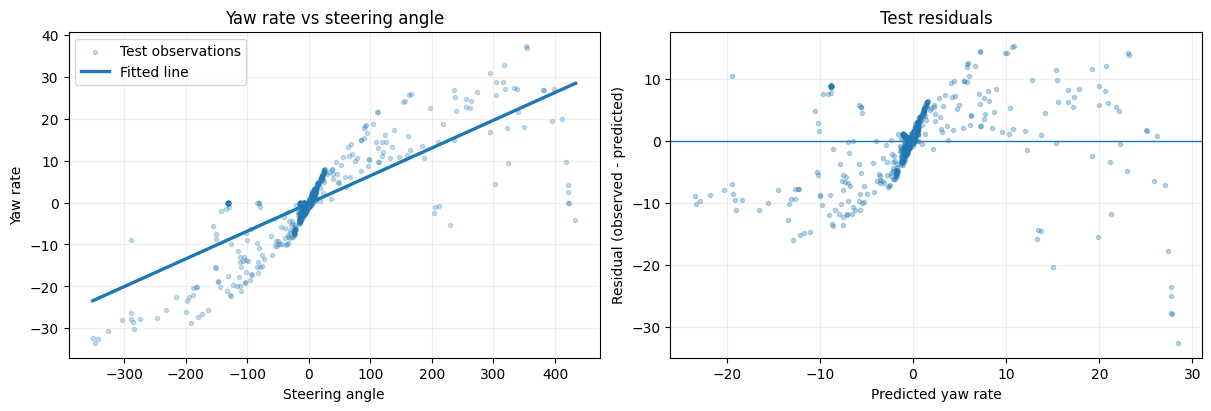

In [68]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12,4), constrained_layout=True)
axes[0].scatter(X_test[:,0], y_test, s=9, alpha=.25, label='Test observations')
x_line = np.linspace(float(X.min()),float(X.max()),200)
axes[0].plot(x_line, sk_model.predict(x_line.reshape(-1,1)),
             linewidth=2.4, label='Fitted line')
axes[0].set(title='Yaw rate vs steering angle',xlabel='Steering angle',ylabel='Yaw rate')
axes[0].legend()
axes[1].scatter(y_pred, y_test-y_pred, alpha=.3, s=9)
axes[1].axhline(0,linewidth=1)
axes[1].set(title='Test residuals',xlabel='Predicted yaw rate',ylabel='Residual (observed - predicted)')
for ax in axes: ax.grid(alpha=.2)
plt.show()

The slope gives the expected change in yaw rate per unit change in steering angle. Test $R^2$ near 1 indicates strong fit, near 0 matches the mean baseline; negative values are worse. Since data are time-indexed, random splits may overestimate performance on future driving sessions.

## Q9 — One-Variable Linear Regression with PyTorch

**Dataset:** Hydropower.csv.  
**Feature:** BCR (Benefit-Cost Ratio).  
**Target:** AnnualProduction.  
**Regression:** $\hat y=w_0+w_1x$ with mini-batch PyTorch SGD and mean-squared error.

We implement `buttercookie.model.regression.LinearRegression` with all required methods. Training inputs and outputs are normalized using only the training set to avoid unstable SGD with large AnnualProduction values; the `predict()` method, fitted coefficients and plotted history are converted back to original data units.

### Q9(a–e) — Package on PyPI, and expose LinearRegression

The model subpackage with regression.py lives in the `buttercookie` UV package (GitHub repo above). After incrementing the version to 0.4.0, the package was built and published to PyPI. The next cell installs the published package from PyPI and imports LinearRegression:



In [69]:
# Q9(f): install the published package from PyPI
!pip install -q buttercookie==0.4.0

from buttercookie.model import LinearRegression
print('Installed buttercookie 0.4.0 from PyPI and imported LinearRegression')

Installed buttercookie 0.4.0 from PyPI and imported LinearRegression


### Q9(d, f) — `fit`, `predict`, and `analysis_plot` on real Hydropower.csv

A 25% holdout is used to demonstrate the required test $R^2$. The original question does not specify a particular holdout fraction for Hydropower, so 25% is a reproducible choice, not an instructor-mandated value for this section.

In [70]:
HYDRO_URL = 'https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv'
hydro_raw = pd.read_csv(HYDRO_URL)
print('Original shape:',hydro_raw.shape)
print('Columns:', hydro_raw.columns.tolist())

data = hydro_raw[['BCR','AnnualProduction']].copy()
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data = data.replace([np.inf,-np.inf],np.nan).dropna()
print('Rows with valid BCR and AnnualProduction:',len(data))
display(data.head())

bcr = data['BCR'].to_numpy(dtype=float)
production = data['AnnualProduction'].to_numpy(dtype=float)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    bcr, production, test_size=0.25, random_state=42
)
print('Training size:',len(Xh_train),'Test size:',len(Xh_test))

Original shape: (191, 9)
Columns: ['FacilityName', 'BCR', 'AnnualProduction', 'ConstructionCost', 'DesignHead', 'Y', 'X1', 'X2', 'X3']
Rows with valid BCR and AnnualProduction: 191


,BCR,AnnualProduction
0,0.02,126
1,0.90,3218
2,0.35,546
3,0.49,1319
4,0.15,238


Training size: 143 Test size: 48


In [71]:
# Train on BCR -> AnnualProduction; output is in original units.
hydro_model = LinearRegression(learning_rate=0.05, epochs=2500,
                               batch_size=32, random_state=42)
hydro_model.fit(Xh_train, yh_train, Xh_test, yh_test)

print()
print('Estimated coefficients:')
print('w0 (intercept) =', hydro_model.intercept_)
print('w1 (slope) =', hydro_model.coef_)
print('R² on test data =', hydro_model.r2_test_)

Fitted model: AnnualProduction = -2875.9526 + (11143.8219) * BCR
Test R²: 0.450439
Final training MSE: 29475450.3279

Estimated coefficients:
w0 (intercept) = -2875.952584028065
w1 (slope) = 11143.821919511915
R² on test data = 0.4504386627927178


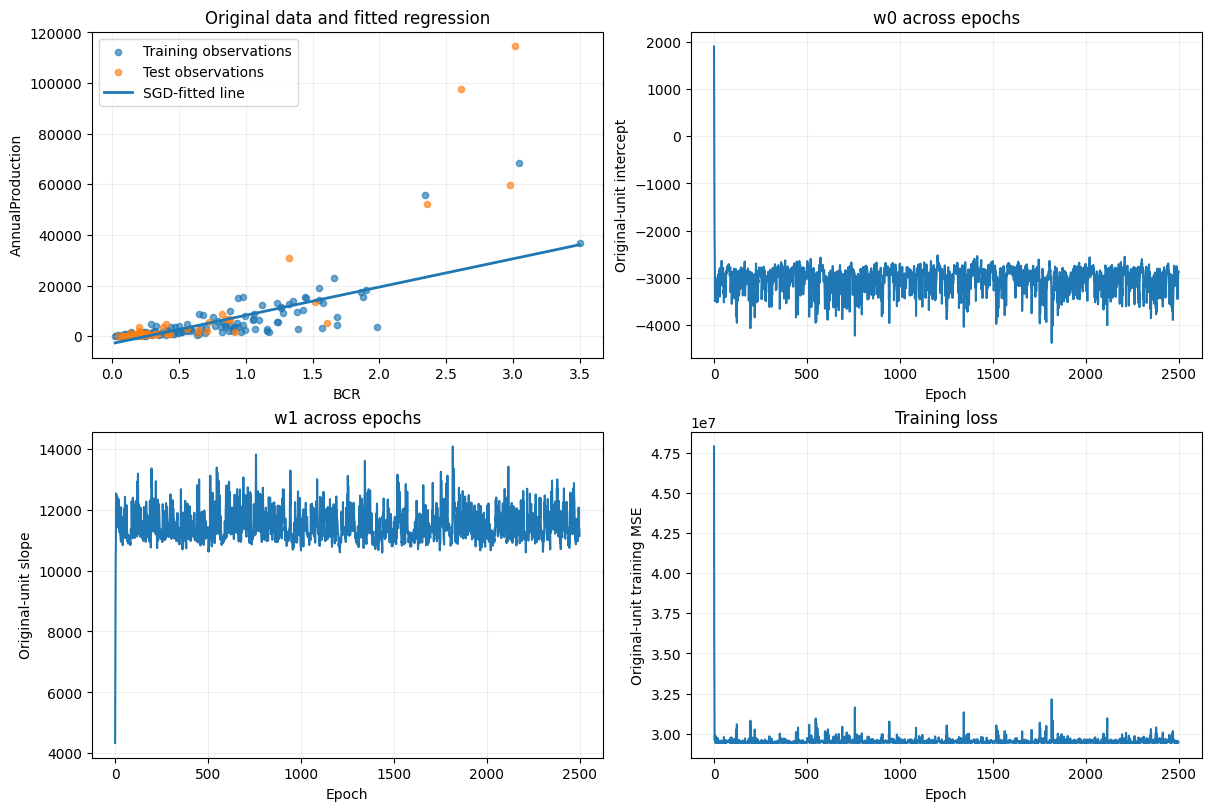

In [72]:
hydro_model.analysis_plot(Xh_train, yh_train, Xh_test, yh_test);